In [11]:
import pandas as pd
from langchain.text_splitter import RecursiveCharacterTextSplitter
import os
import getpass
import warnings
warnings.filterwarnings("ignore")
if not os.environ.get("NVIDIA_API_KEY", "").startswith("nvapi-"):
    nvapi_key = getpass.getpass("Enter your NVIDIA API key: ")
    assert nvapi_key.startswith("nvapi-"), f"{nvapi_key[:5]}... is not a valid key"
    os.environ["NVIDIA_API_KEY"] = nvapi_key


In [146]:
path = '/home/g05_u03/sgp_bootcamp_material/sgp_bootcamp_material/rsm-nvidia-hackathon/data/processed/processed_scraped_dataset.csv'
df = pd.read_csv(path)
df['Raw_Scraped_Text'] = df['Raw_Scraped_Text'].fillna('')

In [131]:
prompt = """
## Instructions
Act as an analyst, for the given submission text, identify:
1. Topics: Extract a comma separated list of topics mentioned, all enclosed in [] brackets using single quotes.
2. Concerns: Extract a comma separated list of concerns raised, all enclosed in [] brackets using single quotes.
3. Risks: Extract a comma separated list of risks outlined, all enclosed in [] brackets using single quotes.
4. Proposals: Extract a comma separated list of proposals outlined, all enclosed in [] brackets using single quotes.
5. Requests to Consider: Extract a comma separated list of requests to be considered, all enclosed in [] brackets using single quotes.
6. Sentiment: Evaluate the overall sentiment as a measure the polarity and emotional range given the authors feedback. The options are: very negative, negative, neutral, positive, very positive.
7. Do not include any sensitive information including personal names, emails and company names.

Generate the above points in a JSON format, ensure the JSON generated is valid and consistent, output well formatted JSON without comments. Respond with only the JSON, do not output any other comments or details other than the JSON.
If there is no submission text provided, output an empty JSON object without comments.
## Submission Text
{0}
 
## JSON Schema
{
    "type": "object",
    "properties": {
        "topics": {"type": "array", "items": {"type": "string"}},
        "concerns": {"type": "array", "items": {"type": "string"}},
        "risks": {"type": "array", "items": {"type": "string"}},
        "proposals": {"type": "array", "items": {"type": "string"}},
        "requests_to_consider": {"type": "array", "items": {"type": "string"}},
        "sentiment": {"type": "string", "pattern": "^((very\s)?negative|neutral|(very\s)?positive)$"}
    },
    "required": ["topics","sentiment"]
}
 
## Generate the strict JSON model
"""

In [135]:
from openai import OpenAI
import json
import re

def llm(chunk):
    client = OpenAI(
    base_url = "https://integrate.api.nvidia.com/v1",
    api_key = "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"
    )

    # Context definition
    LLM_Context = chunk
    
    # Instructions for LLM
    Instructions = prompt
    
    LLM_INPUT = f'''
    ## Context: {LLM_Context}
    
    ## Instructions: {Instructions}
    '''

    completion = client.chat.completions.create(
    model="meta/llama-3.1-405b-instruct",
    messages=[{"role":"user","content":LLM_INPUT}],
    temperature=0,
    top_p=0.7,
    max_tokens=75000,
    stream=True
    )
    
    processed_output = ""

    for chunk in completion:
        if chunk.choices[0].delta.content is not None:
            processed_output += chunk.choices[0].delta.content
            processed_output = re.sub("\s+", " ", processed_output).strip()
    return processed_output


In [149]:
import re
results = []  # To store results for all rows
id_store = []
owner_store = []
count = 1
for _, row in df.iterrows():
    context = row['Raw_Scraped_Text']  # Get the context text from the DataFram
    id = row['URL_ID']
    owner = row['Owner']
    pattern = r'[a-z]{2}'
    # print(context)
    matches = re.search(pattern, context)
    if matches:
        try:
            response = llm(context)  # Call the function with the context
            print(f'context: {row} -- response: {response}')
            processed = response.strip('```')
            data = json.loads(processed)
            results.append(data)
            id_store.append(id)
            owner_store.append(owner)
        except Exception as e:
            print(processed)
            pass
    else:
        pass


context: Unnamed: 0                                                          0
Row_ID                                                              1
URL_ID                                                              1
Owner                                                   CPA Australia
URL_MAIN            https://consult.industry.gov.au/ai-mandatory-g...
Raw_Scraped_Text     \n \nAI Consultation Team  \nIndustry House \...
Document_Name       Submission_Mandatory_Guardrails_for_AI_October...
File_Name           Submission_Mandatory_Guardrails_for_AI_October...
Document_Type                                                     pdf
Directory           C:\\Users\\james.barro\\Documents\\rsm-nvidia-...
Source_Index                                                        1
Name: 0, dtype: object -- response: ```{ "topics": ["'Regulatory options for AI in high-risk settings', 'Definition of high-risk AI', 'Mandatory guardrails for AI', 'Education and tools for safe AI use', 'Impact on small 

In [150]:
processed_df = pd.DataFrame(results) 
processed_df['ID'] = id_store
processed_df = processed_df[['ID'] + [col for col in processed_df.columns if col != 'ID']]
processed_df

,ID,topics,concerns,risks,proposals,requests_to_consider,sentiment
0,1,['Regulatory options for AI in high-risk setti...,"['Unclear definition of high-risk AI', 'Overly...",['Adverse impacts on individuals' physical or ...,['Issue a further consultation paper with clea...,['Tailored regulatory requirements for small b...,neutral
1,3,"['AI regulation', 'guardrails', 'high-risk set...","['inadequate enforcement', 'lack of transparen...","['high-risk AI use cases', 'dark patterns', 'r...","['introducing mandatory guardrails', 'establis...","['banning high-risk AI use cases', 'introducin...",positive
2,5,"['AI in high-risk settings', 'mandatory guardr...",['need for leveling criteria for classifying h...,"['high-risk AI services', 'different risk leve...",['classify risky AI services into6 levels acco...,['collaboration to specify guidelines between ...,positive
3,6,"['AI analytics', 'preventive care', 'regulator...","['market failure', 'unmet support needs', 'dat...","['privacy risks', 'data breaches', 'errors in ...","['mandatory regulatory safeguards', 'framework...","['consistent regulatory baseline', 'sector-spe...",positive
4,7,"['Biometrics', 'Artificial Intelligence', 'Eth...","['Inconsistent use of language', 'Bias', 'Mana...","['Bias in biometric technologies', 'Risks in m...","['Development of guiding materials', 'Training...",['Consideration of the Biometrics Institute's ...,positive
...,...,...,...,...,...,...,...
221,275,"['AI regulation', 'High-risk AI', 'Collective ...","['Inadequate capture of high-risk AI', 'Lack o...","['Unacceptable level of risk in AI use cases',...",['Regulation of AI development and deployment'...,"['Definition of high-risk AI use cases', 'Regu...",negative
222,276,"['High-risk AI', 'Responsible AI', 'AI Governa...","['Model degradation', 'Collapse and unintended...",['Exponential speed of development making guar...,"['MorH tagging standard', 'Accountability proc...","['Banning high-risk use cases', 'Adapting guar...",positive
223,277,"['AI Regulation', 'High-Risk AI', 'GPAI', 'AI ...","['Lack of Indigenous Representation', 'Over-Re...","['Bias in AI Models', 'Data Breaches', 'Cyber-...",['Integration of Indigenous Cultural Protocols...,"['Reducing Regulatory Burden on SMEs', 'Govern...",positive
224,278,"['High-Risk AI', 'AI Governance', 'Transparenc...","['Lack of Uniform Standards', 'Insufficient Ov...","['Unintended Consequences', 'Harm to Individua...","['Proactive Redress Mechanisms', 'Cultural and...","['Risk-Based Approach to Regulation', 'Uniform...",positive


In [153]:
processed_df.to_csv('Processed_df.csv')

In [4]:
from openai import OpenAI
client = OpenAI(
  api_key="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",
  base_url="https://integrate.api.nvidia.com/v1"
)

embedding_outputs = []
per_theme = []
n_id = []
sub_id = []
for _,rows in processed_df.iterrows():
    themes = rows['concerns']
    id = rows['ID']
    for theme in themes:
        tmp_cnt = 1
        for each_theme in theme.split(', '):
            response = client.embeddings.create(
            input=[each_theme],
            model="nvidia/llama-3.2-nv-embedqa-1b-v1",
            encoding_format="float",
            extra_body={"input_type": "passage", "truncate": "NONE"}
    )
            embedding_outputs.append(response.data[0].embedding)        
            per_theme.append(each_theme)   
            n_id.append(id)  
            sub_id.append(tmp_cnt) 
            tmp_cnt+=1

AuthenticationError: Error code: 401 - {'status': 401, 'title': 'Unauthorized', 'detail': 'invalid response from UAM'}

In [155]:
actual_output = pd.DataFrame({'embedding':embedding_outputs, 'theme':per_theme,'id':n_id, 'sub_id':sub_id})

In [156]:
actual_output

,embedding,theme,id,sub_id
0,"[0.0037937164306640625, -0.01312255859375, 0.0...",'Unclear definition of high-risk AI',1,1
1,"[0.017791748046875, -0.01309967041015625, 0.01...",'Overly broad application of mandatory guardra...,1,2
2,"[0.027923583984375, 0.0006346702575683594, 0.0...",'Unintended consequences of regulation',1,3
3,"[0.0223236083984375, -0.0011281967163085938, 0...",'Difficulty for small businesses to comply',1,4
4,"[-0.016571044921875, 0.01506805419921875, 0.03...",'inadequate enforcement',3,1
...,...,...,...,...
1113,"[-0.00012862682342529297, -0.02313232421875, 0...",'Misuse of AI-generated images in wildlife pho...,279,2
1114,"[-0.016754150390625, -0.00860595703125, 0.0155...",'Spread of climate misinformation',279,3
1115,"[-0.015838623046875, -0.0246124267578125, 0.00...",'Objectification of animals',279,4
1116,"[-0.0074615478515625, 0.00182342529296875, 0.0...",'Bias in AI models',279,5


In [1]:
actual_output.to_csv('embeddings.csv')

NameError: name 'actual_output' is not defined

In [157]:
import umap.umap_ as umap

In [158]:
umap_embeddings = umap.UMAP(n_neighbors = 30, min_dist = 0.0, random_state = 42).fit_transform(actual_output['embedding'].tolist())
umap_embeddings

array([[3.1382437, 8.194222 ],
       [8.005231 , 9.886968 ],
       [5.8191953, 1.9409311],
       ...,
       [6.7417197, 4.724476 ],
       [2.3298495, 3.8756175],
       [1.8358778, 7.2712812]], dtype=float32)

Text(0.5, 1.0, 'UMAP Projection of Topic embeddings')

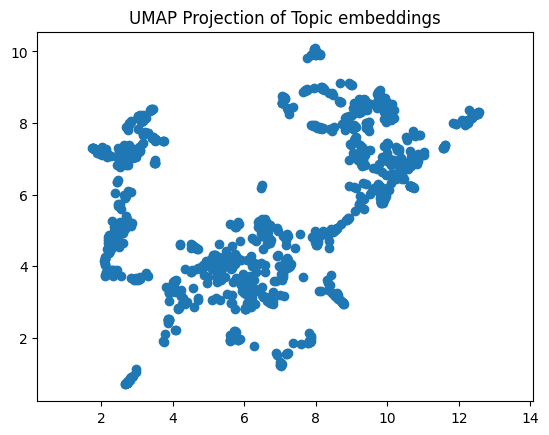

In [159]:
import matplotlib.pyplot as plt

plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP Projection of Topic embeddings')

In [160]:
import sklearn.cluster as cluster
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

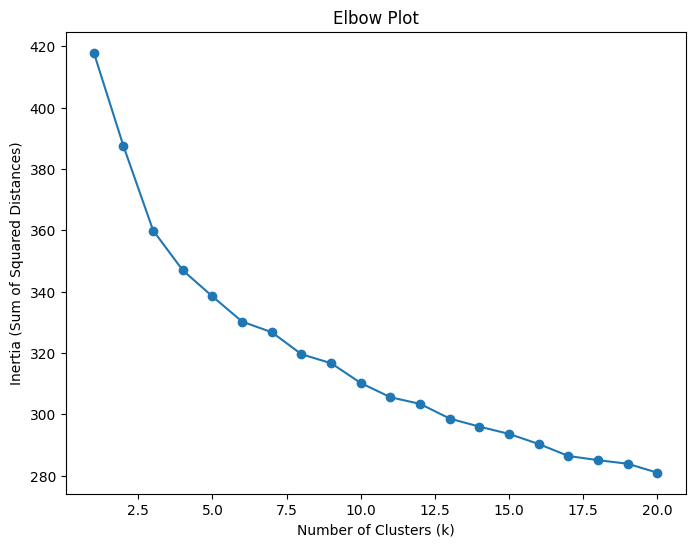

In [169]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import numpy as np

# Example data (replace with your own data)
X = actual_output['embedding'].tolist()

# Range of k values to test (e.g., from 1 to 10 clusters)
k_range = range(1, 21)

# List to store the sum of squared distances for each k
inertia_values = []

# Fit KMeans for each k and store the inertia (within-cluster sum of squares)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)  # X is your data
    inertia_values.append(kmeans.inertia_)

# Plot the elbow plot
plt.figure(figsize=(8, 6))
plt.plot(k_range, inertia_values, marker='o')
plt.title('Elbow Plot')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Sum of Squared Distances)')
plt.show()


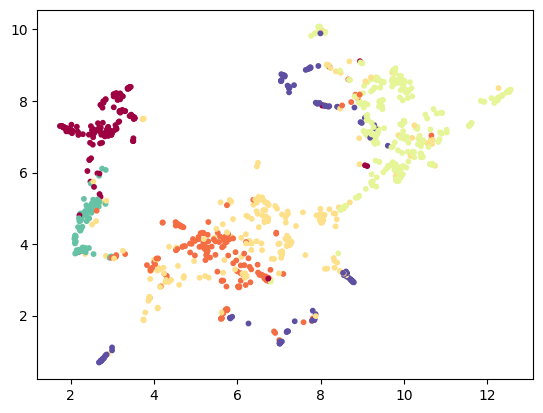

In [177]:
#try with 6 clusters:

kmeans_labels = cluster.KMeans(n_clusters = 6, random_state = 81).fit_predict(actual_output['embedding'].tolist())
plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], c = kmeans_labels, s = 10, cmap = 'Spectral' )

In [178]:
umap_df = pd.DataFrame(umap_embeddings, columns = ('x', 'y'))
umap_df['themes_embedding'] = actual_output['embedding'].tolist()
umap_df['cluster'] = kmeans_labels
umap_df['themes'] = actual_output['theme']
umap_df['id'] = actual_output['id']
umap_df['sub_id'] = actual_output['sub_id']

In [179]:
umap_df

,x,y,themes_embedding,cluster,themes,id,sub_id
0,3.138244,8.194222,"[0.0037937164306640625, -0.01312255859375, 0.0...",0,'Unclear definition of high-risk AI',1,1
1,8.005231,9.886968,"[0.017791748046875, -0.01309967041015625, 0.01...",3,'Overly broad application of mandatory guardra...,1,2
2,5.819195,1.940931,"[0.027923583984375, 0.0006346702575683594, 0.0...",5,'Unintended consequences of regulation',1,3
3,8.621743,3.092770,"[0.0223236083984375, -0.0011281967163085938, 0...",5,'Difficulty for small businesses to comply',1,4
4,9.323815,6.898623,"[-0.016571044921875, 0.01506805419921875, 0.03...",3,'inadequate enforcement',3,1
...,...,...,...,...,...,...,...
1113,2.632772,5.139551,"[-0.00012862682342529297, -0.02313232421875, 0...",4,'Misuse of AI-generated images in wildlife pho...,279,2
1114,2.510849,4.546305,"[-0.016754150390625, -0.00860595703125, 0.0155...",2,'Spread of climate misinformation',279,3
1115,6.741720,4.724476,"[-0.015838623046875, -0.0246124267578125, 0.00...",2,'Objectification of animals',279,4
1116,2.329849,3.875618,"[-0.0074615478515625, 0.00182342529296875, 0.0...",4,'Bias in AI models',279,5


In [180]:
#interactive plots - use bokeh package

from bokeh.plotting import figure, show, output_notebook
from bokeh.models import HoverTool, ColumnDataSource, CategoricalColorMapper
from bokeh.palettes import Spectral10
from bokeh.transform import factor_cmap

output_notebook()
#need to convert cluster column to string for color mapping to work!
umap_df['cluster'] = umap_df['cluster'].astype(str)
datasource = ColumnDataSource(umap_df)

Loading BokehJS ...

In [188]:
plot_figure = figure(title = 'AI Guardrails Themes', 
                     width = 800, 
                     height = 600, 
                     tooltips = "cluster @cluster - @themes")

plot_figure.circle('x',
                  'y', 
                  source = datasource,
                  line_alpha = 0.6, 
                  fill_alpha = 0.6, 
                  color = factor_cmap('cluster', Spectral10, ['0','1','2','3','4','5','6']),
                  size = 6)

GlyphRenderer(id='p1318', ...)

In [189]:
show(plot_figure)

In [205]:
tmp_doc = umap_df[umap_df['cluster'] == '1']['themes']
tmp_doc.to_csv('tmp_doc.csv')